In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno

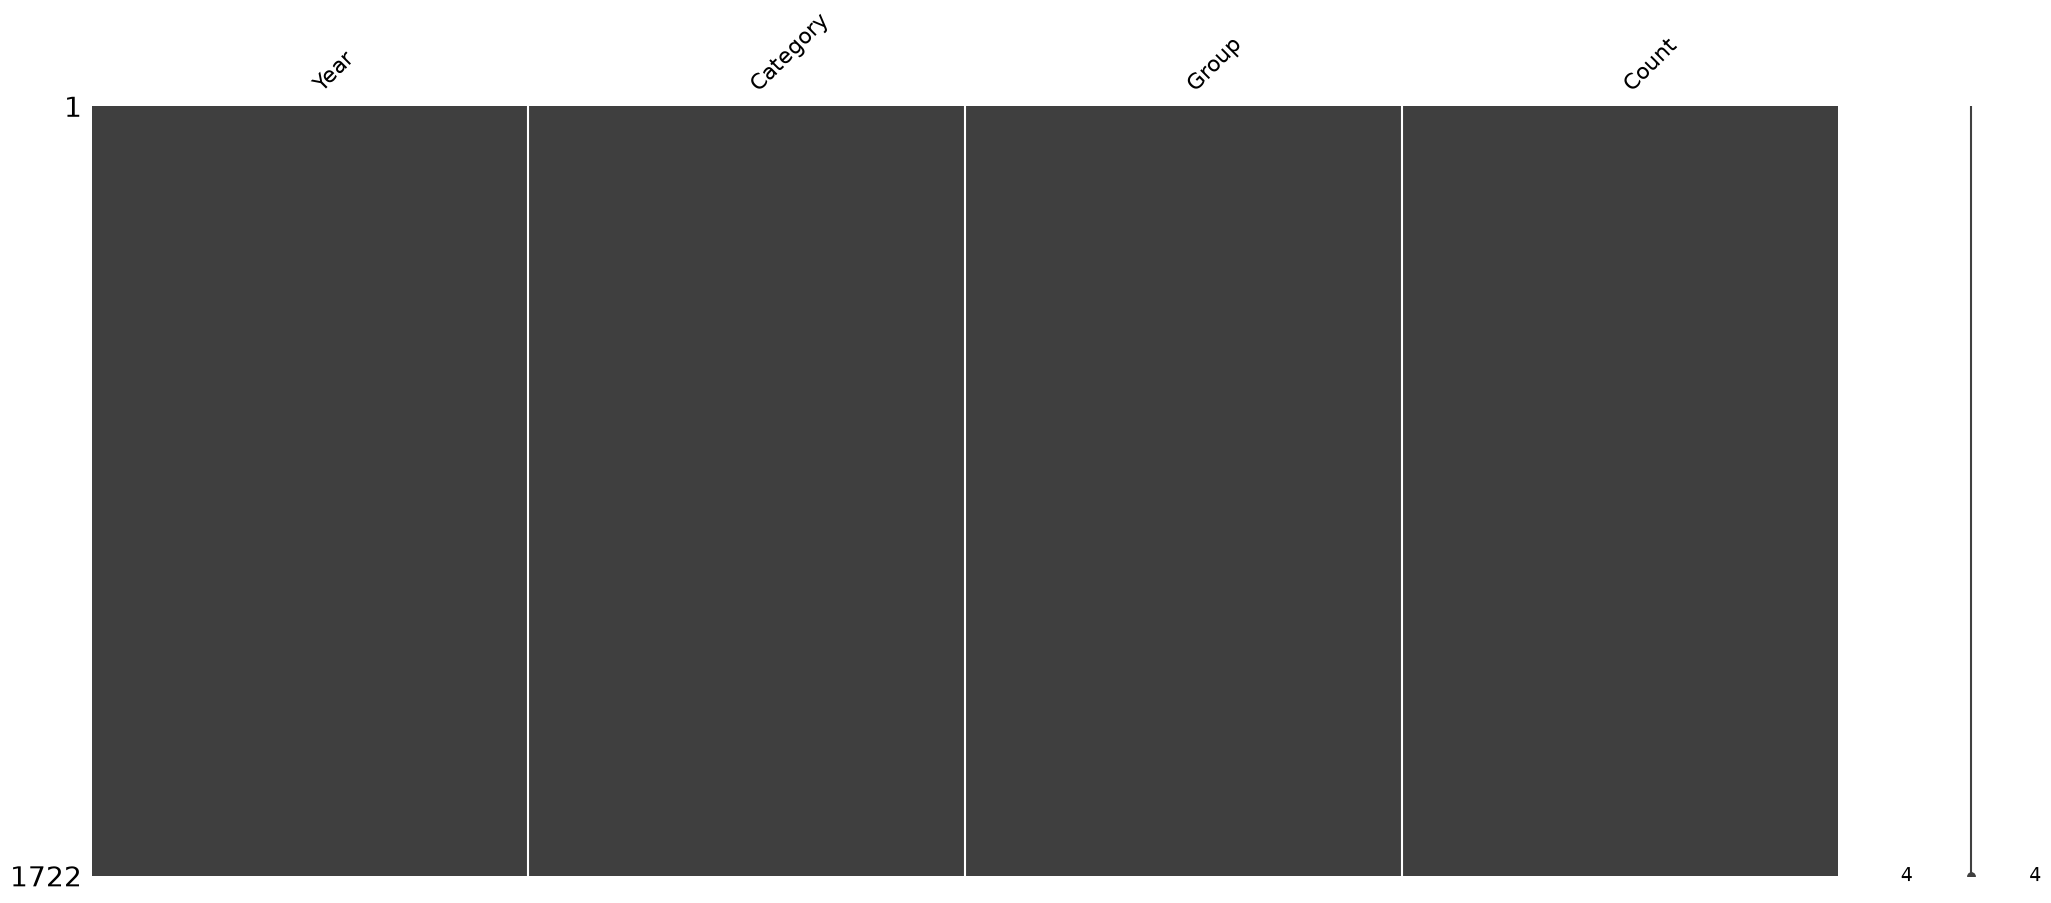

In [2]:
persons_living_with_hiv_aids = pd.read_csv("persons-living-with-hiv-aids.csv")
msno.matrix(persons_living_with_hiv_aids)
plt.show()

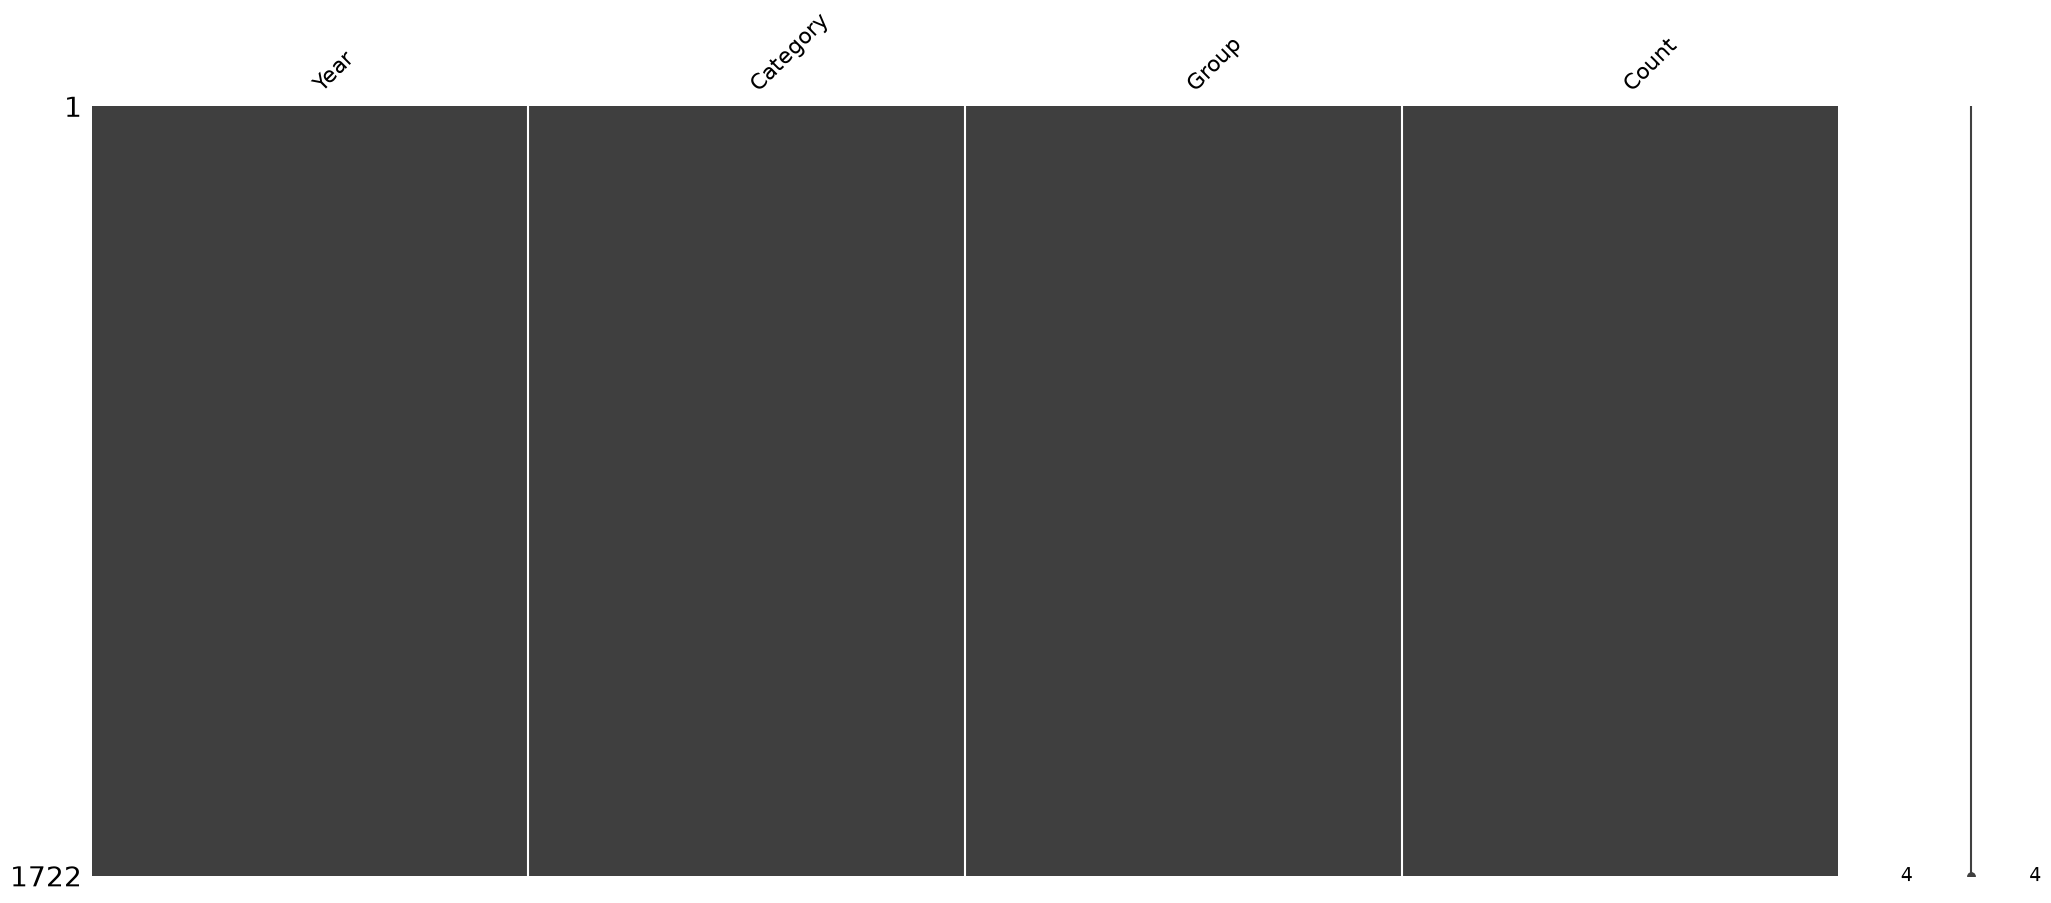

In [4]:
persons_newly_diagnosed_with_hiv = pd.read_csv("persons-newly-diagnosed-with-hiv.csv")
msno.matrix(persons_newly_diagnosed_with_hiv)
plt.show()

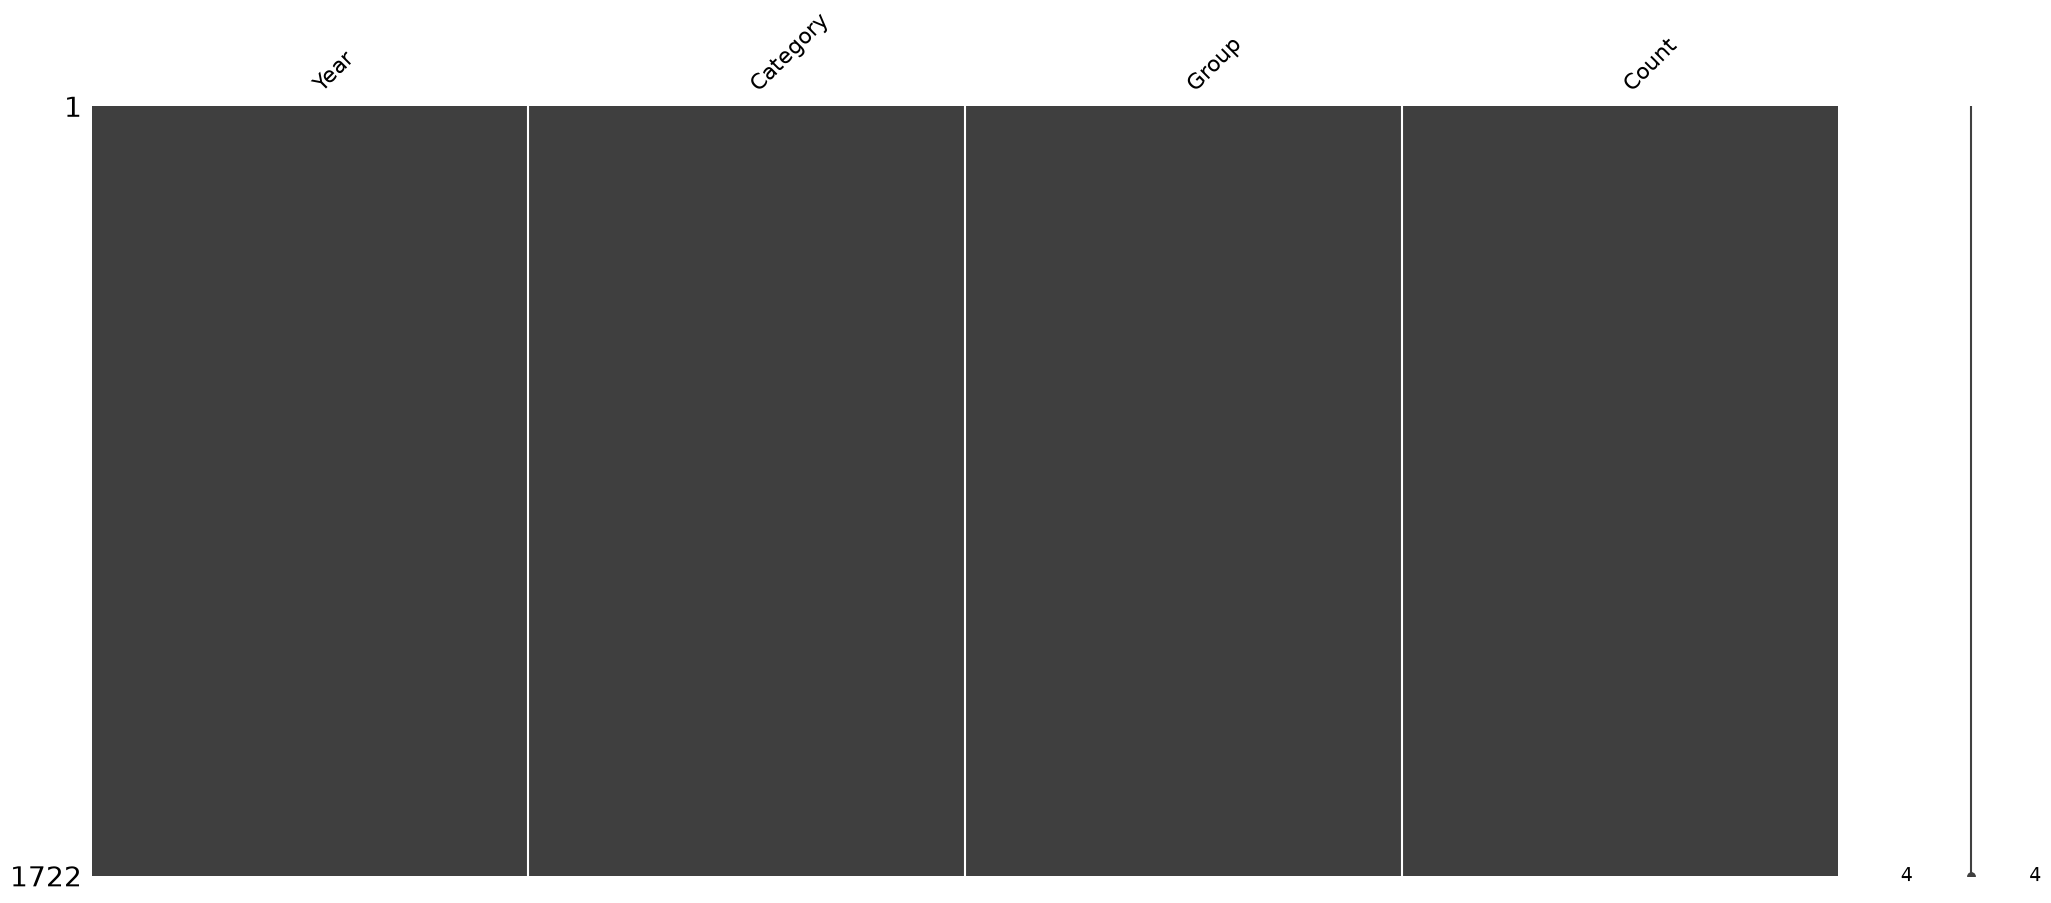

In [5]:
deaths_of_persons_diagnosed_with_hiv_aids = pd.read_csv("deaths-of-persons-diagnosed-with-hiv-aids.csv")
msno.matrix(deaths_of_persons_diagnosed_with_hiv_aids)
plt.show()

In [6]:
df1 = persons_living_with_hiv_aids.rename(columns={'Count': 'Count_Living'})
df2 = persons_newly_diagnosed_with_hiv.rename(columns={'Count': 'Count_New'})
df3 = deaths_of_persons_diagnosed_with_hiv_aids.rename(columns={'Count': 'Count_Deaths'})

combined = (
    df1
    .merge(df2, on=['Year', 'Category', 'Group'])
    .merge(df3, on=['Year', 'Category', 'Group'])
)

combined.head(10)

combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 658 entries, 0 to 657
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Year          658 non-null    int64
 1   Category      658 non-null    str  
 2   Group         658 non-null    str  
 3   Count_Living  658 non-null    int64
 4   Count_New     658 non-null    int64
 5   Count_Deaths  658 non-null    int64
dtypes: int64(4), str(2)
memory usage: 31.0 KB


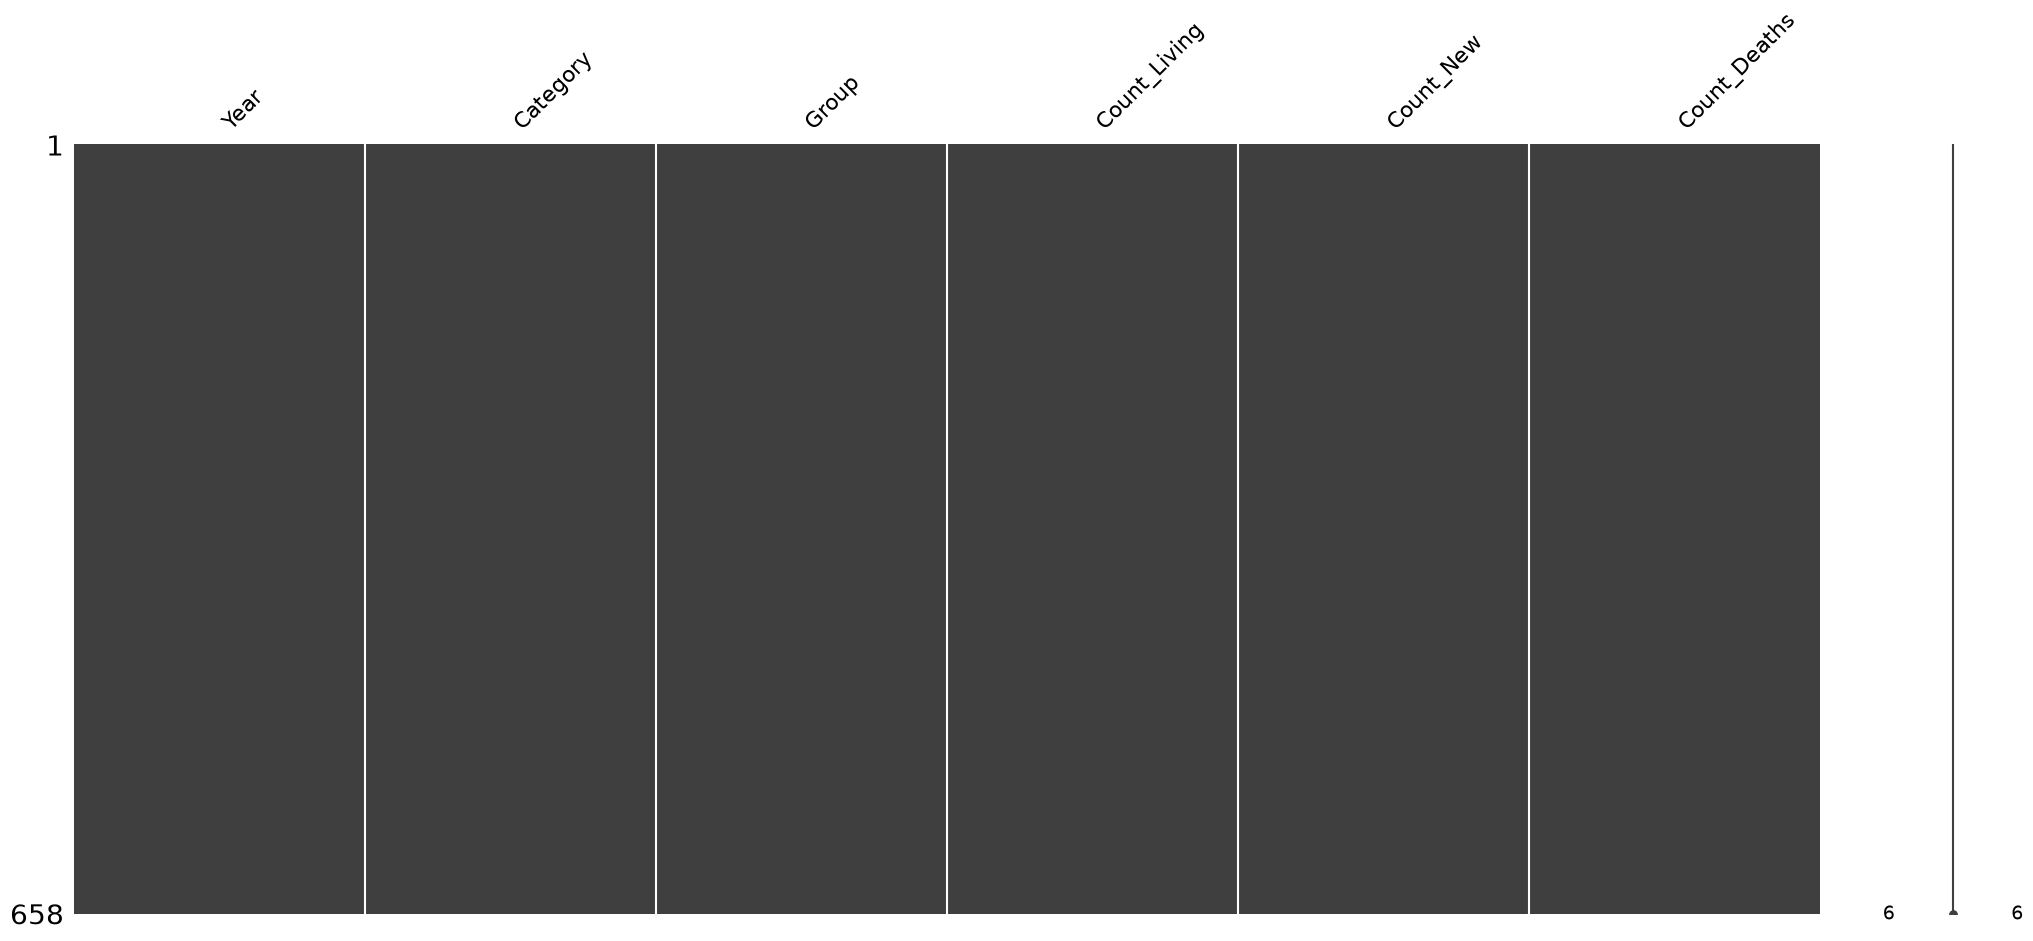

In [9]:
msno.matrix(combined)
plt.show()

In [7]:
measure_cols = ['Count_Living', 'Count_New', "Count_Deaths"]
grp_by = combined.groupby(['Year', 'Category'])[measure_cols].mean()

print(grp_by)

                                                         Count_Living  \
Year Category                                                           
2010 Current Gender                                      23123.400000   
     Race/Ethnicity                                      14452.125000   
     Sex at Birth                                        57808.500000   
     Transmission Category: Alternative Gender Adult...      0.600000   
     Transmission Category: Child (<12 Years Old at ...     58.000000   
...                                                               ...   
2023 Transmission Category: Child (<12 Years Old at ...     21.000000   
     Transmission Category: Cisgender Men Adult or A...  15376.250000   
     Transmission Category: Cisgender Women Adult or...   2843.166667   
     Transmission Category: Trans Men Adult or Adole...     22.400000   
     Transmission Category: Trans Women Adult or Ado...    590.400000   

                                                  